# Modelo supervisado de peso al nacer
### Fetal Medical Bolivia · Proyecto Integrador 2026 · UNIFRANZ

**Qué hace, en una frase:** mide la cabeza, el abdomen y el fémur del bebé en la
ecografía y, con eso y algunos datos de la madre, **predice cuánto va a pesar al
nacer**. De ese peso saca una clase: **bajo peso** (< 2.500 g), **normal** o
**macrosomía** (> 4.000 g).

**Tipo de modelo:** aprendizaje **supervisado** de **regresión**. Aprende de
bebés que ya nacieron —de los que se conocen las medidas y el peso real— y
aplica esa relación a los que todavía no han nacido. La clasificación no se
entrena aparte: sale de aplicar los cortes al peso previsto.

**En qué parte del sistema está:** en el módulo `ia_medica`, subcarpeta
`ia_medica/ml/`. Se alimenta del módulo `ecografias` (la biometría) y aprende
de `partos` (el peso real del recién nacido).

| Paso | Qué se hace |
|---|---|
| 1 | Importación de librerías |
| 2 | Carga de datos |
| 3 | Exploración de datos |
| 4 | Definición de variables de entrada (X) y objetivo (y) |
| 5 | Crear y entrenar el modelo |
| 6 | Hacer predicciones |
| 7 | Evaluar el modelo |
| 8 | Gráficas de la evaluación (R², ROC…) y cómo implementarlo |

> **Aviso importante.** Los 5.000 casos son **simulados** con curvas de
> crecimiento publicadas (Hadlock 1991). No son pacientes reales. El modelo
> recupera la relación con la que se generaron los datos: esto sirve para
> **enseñar cómo funciona**, no para afirmar nada sobre la población boliviana.

---
## Paso 1: Importación de librerías

- **pandas** y **numpy**: manejar la tabla de datos y hacer cuentas.
- **matplotlib**: las gráficas.
- **scikit-learn**: los modelos de aprendizaje automático y sus métricas.

Se fija una **semilla** (`2026`) para que cada vez que se ejecute el notebook
salgan exactamente los mismos resultados. Sin eso no se podría comparar nada.

In [1]:
# Paso 1: Importación de librerías
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split, KFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.base import clone
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    roc_curve, roc_auc_score, confusion_matrix, classification_report,
)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
SEMILLA = 2026
np.random.seed(SEMILLA)

# Los mismos colores que el documento del modelo:
# azul = el modelo, ocre = la fórmula de Hadlock, rojo = errores.
AZUL, OCRE, ROJO, VERDE, GRIS = "#2e5b86", "#9a7327", "#a8412f", "#2b7656", "#9aa4a8"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
})

print(f"pandas {pd.__version__}  ·  numpy {np.__version__}  ·  scikit-learn {sklearn.__version__}")

pandas 2.3.3  ·  numpy 2.4.6  ·  scikit-learn 1.8.0


---
## Paso 2: Carga de datos

Se lee el Excel `datos/muestra_peso_nacimiento.xlsx`. Tiene cuatro hojas:

| Hoja | Contenido |
|---|---|
| **Muestra** | 5.000 embarazos simulados, una fila por bebé. Es la que se usa aquí. |
| **Diccionario** | Qué significa cada columna, su unidad y su papel. |
| **Resumen** | Conteos y medias por clase, para mirar sin programar. |
| **Dataset_sistema** | Las 277 filas que el sistema construye desde su base de datos. |

Cada fila es **un bebé**: la ecografía que se le hizo antes de nacer, los datos
de su madre, y el peso con el que nació.

In [2]:
# Paso 2: Carga de datos
RUTA = Path("datos/muestra_peso_nacimiento.xlsx")

df = pd.read_excel(RUTA, sheet_name="Muestra")
diccionario = pd.read_excel(RUTA, sheet_name="Diccionario")

print(f"Filas: {len(df):,}   ·   Columnas: {df.shape[1]}".replace(",", "."))
df.head(8)

Filas: 5.000   ·   Columnas: 22


,id_paciente,dbp_mm,cc_mm,ca_mm,lf_mm,relacion_cc_ca,relacion_lf_ca,peso_hadlock_g,eg_eco_semanas,eg_al_nacer_semanas,...,numero_para,numero_abortos,numero_cesareas,diabetes,hipertension,preeclampsia_previa,diabetes_gestacional_previa,peso_hadlock_proyectado_g,peso_nacimiento_g,clase_peso
0,P00001,75.6,274.4,243.8,54.5,1.1255,0.2235,1316,28.10,37,...,2,0,0,0,0,0,0,3248,3028,normal
1,P00002,77.4,289.2,265.8,60.1,1.0880,0.2261,1694,30.85,39,...,3,0,0,1,0,0,0,3378,3663,normal
2,P00003,88.8,325.6,308.5,66.5,1.0554,0.2156,2579,34.69,40,...,1,0,0,0,0,0,0,3693,4208,macrosomia
3,P00004,73.5,276.9,257.9,55.6,1.0737,0.2156,1454,29.43,38,...,1,2,0,0,0,0,0,3231,3187,normal
4,P00005,68.5,245.6,212.5,49.1,1.1558,0.2311,913,26.37,36,...,1,0,0,1,0,0,0,2659,2988,normal
5,P00006,74.6,280.4,266.6,57.8,1.0518,0.2168,1601,30.74,40,...,0,1,0,0,0,0,0,3406,3196,normal
6,P00007,82.3,297.5,281.6,63.5,1.0565,0.2255,2008,30.70,37,...,0,0,0,0,0,0,0,3589,3107,normal
7,P00008,79.7,312.1,287.3,63.4,1.0863,0.2207,2090,33.91,40,...,3,0,0,0,0,0,1,3207,3538,normal


**El diccionario de columnas.** La columna *papel* dice qué hace cada una:
**entrada** (lo que el modelo recibe), **objetivo** (lo que aprende a predecir),
**comparador** (contra qué se le mide) o **identificador**.

In [3]:
pd.set_option("display.max_colwidth", 80)
diccionario

,columna,descripcion,unidad,papel
0,id_paciente,Identificador de la paciente simulada,—,identificador
1,dbp_mm,Diámetro biparietal: ancho de la cabeza,mm,entrada
2,cc_mm,Circunferencia cefálica: contorno de la cabeza,mm,entrada
3,ca_mm,Circunferencia abdominal: contorno del abdomen,mm,entrada
4,lf_mm,Longitud del fémur,mm,entrada
5,relacion_cc_ca,Cabeza / abdomen. Alta en fetos delgados,cociente,entrada
6,relacion_lf_ca,Fémur / abdomen,cociente,entrada
7,peso_hadlock_g,Peso por la fórmula de Hadlock EL DÍA DE LA ECO,g,entrada
8,eg_eco_semanas,Semanas de embarazo el día de la ecografía,semanas,entrada
9,eg_al_nacer_semanas,Semanas de embarazo al nacer (en consulta: la que pregunta la médica),semanas,entrada


---
## Paso 3: Exploración de datos

Antes de entrenar nada hay que mirar los datos: si faltan valores, cómo se
reparten las clases, y si de verdad hay una relación que aprender. **Un modelo
entrenado sobre datos sin relación aprende ruido**, y su métrica no significa
nada.

### 3.1 Tipos de dato y valores que faltan

In [4]:
faltan = df.isna().sum()
pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "valores que faltan": faltan,
    "% que falta": (faltan / len(df) * 100).round(1),
}).query("`valores que faltan` > 0 or tipo == 'object'")

,tipo,valores que faltan,% que falta
id_paciente,object,0,0.0
imc_pregestacional,float64,383,7.7
clase_peso,object,0,0.0


El **IMC** falta en aproximadamente un 8% de los casos, que es lo que ocurre en
una clínica: no siempre se registra. No se borran esas filas ni se rellena con
un número inventado; el modelo aprende qué hacer cuando falta (paso 5).

### 3.2 Estadísticas de las variables principales

In [5]:
principales = ["dbp_mm", "cc_mm", "ca_mm", "lf_mm", "eg_eco_semanas",
               "eg_al_nacer_semanas", "edad_materna", "imc_pregestacional",
               "peso_hadlock_proyectado_g", "peso_nacimiento_g"]
df[principales].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
dbp_mm,5000.0,84.0,8.3,46.4,78.7,84.8,90.1,105.9
cc_mm,5000.0,303.4,30.7,165.0,283.8,305.0,325.0,381.3
ca_mm,5000.0,293.5,37.6,145.7,267.4,294.6,321.0,388.9
lf_mm,5000.0,64.4,7.5,32.5,59.5,64.7,70.0,83.4
eg_eco_semanas,5000.0,33.4,3.6,20.0,31.0,33.4,36.1,41.5
eg_al_nacer_semanas,5000.0,38.6,2.3,28.0,37.0,39.0,40.0,42.0
edad_materna,5000.0,27.0,5.8,15.0,23.0,27.0,31.0,45.0
imc_pregestacional,4617.0,24.6,3.9,16.0,21.9,24.6,27.2,40.3
peso_hadlock_proyectado_g,5000.0,3379.6,624.0,1060.0,3005.0,3378.0,3793.0,5665.0
peso_nacimiento_g,5000.0,3282.4,601.1,881.0,2931.0,3308.0,3676.2,5251.0


### 3.3 ¿Cómo se reparten las clases y el peso?

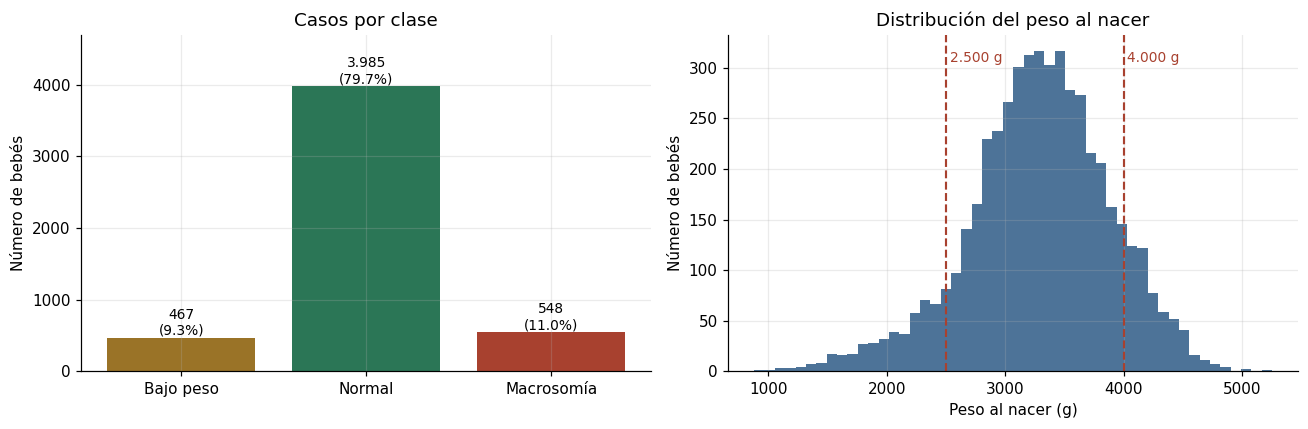

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))

orden = ["bajo_peso", "normal", "macrosomia"]
colores = [OCRE, VERDE, ROJO]
conteo = df["clase_peso"].value_counts().reindex(orden)
barras = a1.bar(["Bajo peso", "Normal", "Macrosomía"], conteo.values, color=colores)
for b, n in zip(barras, conteo.values):
    a1.text(b.get_x() + b.get_width() / 2, n + 40, f"{n:,}\n({n / len(df):.1%})".replace(",", "."),
            ha="center", fontsize=9)
a1.set_title("Casos por clase")
a1.set_ylabel("Número de bebés")
a1.set_ylim(0, conteo.max() * 1.18)

a2.hist(df["peso_nacimiento_g"], bins=50, color=AZUL, alpha=0.85)
for corte, nombre in [(2500, "2.500 g"), (4000, "4.000 g")]:
    a2.axvline(corte, color=ROJO, ls="--", lw=1.4)
    a2.text(corte + 30, a2.get_ylim()[1] * 0.92, nombre, color=ROJO, fontsize=9)
a2.set_title("Distribución del peso al nacer")
a2.set_xlabel("Peso al nacer (g)")
a2.set_ylabel("Número de bebés")
plt.tight_layout()
plt.show()

**Las clases están desbalanceadas**: ~80% de los bebés tienen peso normal. Eso
importa para evaluar: un modelo que dijera siempre «normal» acertaría el 80% de
las veces sin servir para nada. Por eso en el paso 7 no se mira el acierto
global, sino **cuántos casos de cada clase detecta**.

### 3.4 ¿Hay una relación que aprender?

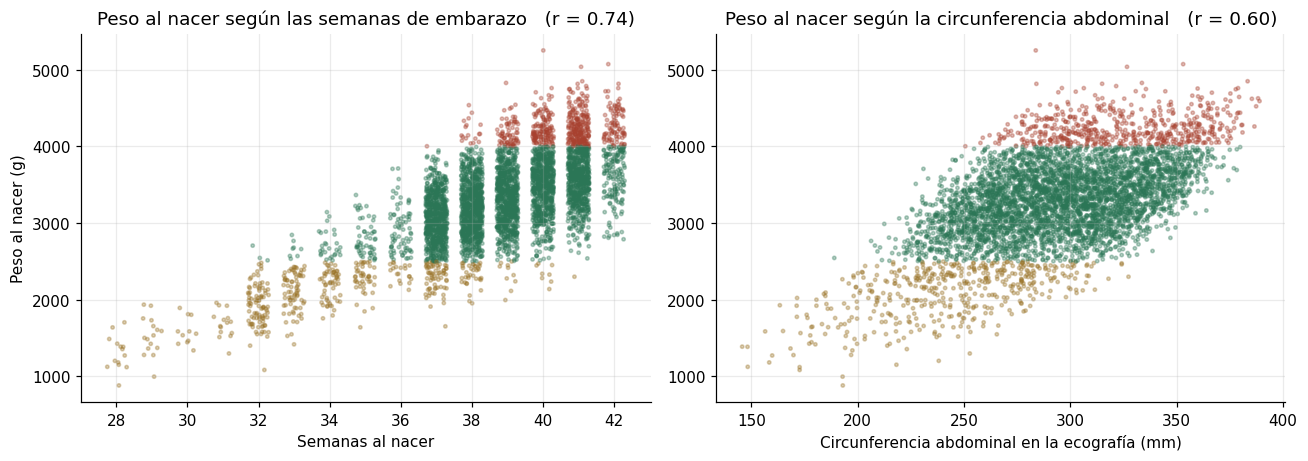

In [7]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.3))
color_clase = df["clase_peso"].map({"bajo_peso": OCRE, "normal": VERDE, "macrosomia": ROJO})

r1 = df["eg_al_nacer_semanas"].corr(df["peso_nacimiento_g"])
a1.scatter(df["eg_al_nacer_semanas"] + np.random.uniform(-.3, .3, len(df)),
           df["peso_nacimiento_g"], s=5, alpha=0.35, c=color_clase)
a1.set_title(f"Peso al nacer según las semanas de embarazo   (r = {r1:.2f})")
a1.set_xlabel("Semanas al nacer")
a1.set_ylabel("Peso al nacer (g)")

r2 = df["ca_mm"].corr(df["peso_nacimiento_g"])
a2.scatter(df["ca_mm"], df["peso_nacimiento_g"], s=5, alpha=0.35, c=color_clase)
a2.set_title(f"Peso al nacer según la circunferencia abdominal   (r = {r2:.2f})")
a2.set_xlabel("Circunferencia abdominal en la ecografía (mm)")
plt.tight_layout()
plt.show()

Sí: el peso sube con las semanas y con el tamaño del abdomen. La **r de
Pearson** mide esa relación de −1 a 1; por encima de 0,5 es una relación
fuerte. En la versión anterior del generador de datos del proyecto, esta r
valía **exactamente 0**: el peso se sorteaba sin mirar las semanas.

### 3.5 ¿Qué variable se relaciona más con el peso?

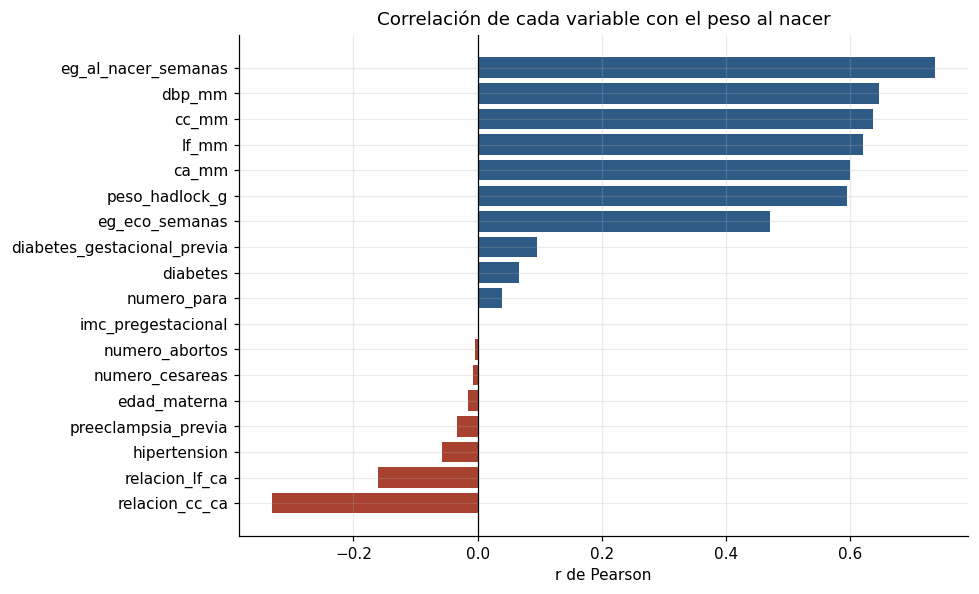

In [8]:
entradas_numericas = [c for c in diccionario.query("papel == 'entrada'")["columna"]]
correlaciones = (df[entradas_numericas + ["peso_nacimiento_g"]]
                 .corr()["peso_nacimiento_g"].drop("peso_nacimiento_g")
                 .sort_values())

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(correlaciones.index, correlaciones.values,
        color=[AZUL if v > 0 else ROJO for v in correlaciones.values])
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Correlación de cada variable con el peso al nacer")
ax.set_xlabel("r de Pearson")
plt.tight_layout()
plt.show()

### 3.6 Medias por clase

In [9]:
(df.groupby("clase_peso")
   [["peso_nacimiento_g", "eg_al_nacer_semanas", "ca_mm", "imc_pregestacional", "diabetes"]]
   .mean().reindex(orden).round(2))

,peso_nacimiento_g,eg_al_nacer_semanas,ca_mm,imc_pregestacional,diabetes
clase_peso,,,,,
bajo_peso,2086.84,34.06,243.17,24.78,0.02
normal,3289.11,38.87,295.01,24.62,0.04
macrosomia,4252.89,40.56,325.37,24.61,0.05


---
## Paso 4: Definición de variables de entrada (X) y objetivo (y)

- **X** son las **18 variables de entrada**: lo que se sabe el día de la
  ecografía.
- **y** es el **objetivo**: el peso al nacer, en gramos.

Hay columnas que **no entran en X a propósito**, porque darían un resultado
engañoso:

| Columna | Por qué NO entra |
|---|---|
| `peso_nacimiento_g` | Es la respuesta. Meterla sería darle al modelo la solución. |
| `clase_peso` | Sale del peso real. Misma razón. |
| `peso_hadlock_proyectado_g` | Es el **comparador**. Si entrara, el modelo podría limitarse a copiarlo. |
| `id_paciente` | Es un identificador, no un dato clínico. |

**Sobre `eg_al_nacer_semanas`:** es la variable más importante y, el día de la
ecografía, no se sabe cuándo va a nacer el bebé. Por eso en el sistema **la
pregunta la hace la médica**: «¿cuánto pesaría si nace a las 39 semanas?».

Después se separan los datos: **80% para entrenar** y **20% para probar**. El
modelo nunca ve el 20% de prueba mientras aprende; así se mide cómo le iría con
bebés nuevos. La separación es **estratificada**: las tres clases quedan en la
misma proporción en los dos grupos.

In [10]:
# Paso 4: Definición de variables de entrada (X) y objetivo (y)
ENTRADAS = [
    # Biometría de la ecografía
    "dbp_mm", "cc_mm", "ca_mm", "lf_mm",
    "relacion_cc_ca", "relacion_lf_ca", "peso_hadlock_g",
    # Tiempo
    "eg_eco_semanas", "eg_al_nacer_semanas",
    # Madre
    "edad_materna", "imc_pregestacional",
    "numero_para", "numero_abortos", "numero_cesareas",
    # Antecedentes
    "diabetes", "hipertension", "preeclampsia_previa", "diabetes_gestacional_previa",
]
OBJETIVO = "peso_nacimiento_g"
COMPARADOR = "peso_hadlock_proyectado_g"

X = df[ENTRADAS]
y = df[OBJETIVO]

X_ent, X_pru, y_ent, y_pru, clase_ent, clase_pru, hadlock_ent, hadlock_pru = train_test_split(
    X, y, df["clase_peso"], df[COMPARADOR],
    test_size=0.20, random_state=SEMILLA, stratify=df["clase_peso"],
)

print(f"Variables de entrada (X): {X.shape[1]}")
print(f"Entrenamiento: {len(X_ent):,} bebés".replace(",", "."))
print(f"Prueba:        {len(X_pru):,} bebés".replace(",", "."))
print()
print(pd.DataFrame({
    "entrenamiento": clase_ent.value_counts(normalize=True).reindex(orden),
    "prueba": clase_pru.value_counts(normalize=True).reindex(orden),
}).map(lambda v: f"{v:.1%}"))

Variables de entrada (X): 18
Entrenamiento: 4.000 bebés
Prueba:        1.000 bebés

           entrenamiento prueba
clase_peso                     
bajo_peso           9.3%   9.3%
normal             79.7%  79.7%
macrosomia         10.9%  11.0%


---
## Paso 5: Crear y entrenar el modelo

Se entrenan **tres modelos** sobre los mismos datos, para poder compararlos:

| Modelo | Cómo funciona |
|---|---|
| **Ridge** | Una suma ponderada: *peso = base + a·variable₁ + b·variable₂ + …* Aprende cuánto aporta cada variable. Es el que usa el sistema. |
| **Random Forest** | 300 árboles de decisión que hacen preguntas («¿el abdomen mide más de 310 mm?») y promedian sus respuestas. |
| **Gradient Boosting** | Árboles en cadena: cada uno corrige los errores del anterior. |

Cada modelo es un **pipeline**, una cadena de pasos que se aplica igual al
entrenar y al predecir:

1. **`SimpleImputer`**: rellena el IMC que falta con la mediana *del
   entrenamiento* (nunca de la prueba: eso sería mirar las respuestas).
2. **`StandardScaler`**: pone todas las variables en la misma escala. Sin esto,
   Ridge trataría distinto un fémur en milímetros que una edad en años.
3. **El modelo** en sí.

`.fit()` es el momento en que **aprende**: recorre los ejemplos de
entrenamiento y ajusta sus números internos para equivocarse lo menos posible.

In [11]:
# Paso 5: Crear y entrenar el modelo
modelos = {
    "Ridge": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        Ridge(alpha=1.0),
    ),
    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                              random_state=SEMILLA, n_jobs=-1),
    ),
    "Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
        min_samples_leaf=10, l2_regularization=1.0, random_state=SEMILLA,
    ),
}

for nombre, modelo in modelos.items():
    inicio = time.perf_counter()
    modelo.fit(X_ent, y_ent)          # <- aquí aprende
    ms = (time.perf_counter() - inicio) * 1000
    print(f"{nombre:<18} entrenado en {ms:7.0f} ms")

Ridge              entrenado en       7 ms


Random Forest      entrenado en     504 ms


Gradient Boosting  entrenado en    1835 ms


### 5.1 Qué aprendió Ridge

Ridge es fácil de explicar porque lo que aprende es **una suma**. Cada
coeficiente dice **cuántos gramos cambia el peso previsto** cuando esa variable
sube una desviación típica (por ejemplo, un abdomen que mide unos 15 mm más que
la media para su semana).

In [12]:
ridge = modelos["Ridge"]
coeficientes = pd.Series(ridge[-1].coef_, index=ENTRADAS).sort_values(key=abs, ascending=False)

print(f"Peso base (intercepto): {ridge[-1].intercept_:,.0f} g\n".replace(",", "."))
pd.DataFrame({
    "gramos por desviación típica": coeficientes.round(0).astype(int),
    "efecto": np.where(coeficientes > 0, "sube el peso", "baja el peso"),
})

Peso base (intercepto): 3.279 g



,gramos por desviación típica,efecto
eg_eco_semanas,-936,baja el peso
eg_al_nacer_semanas,431,sube el peso
ca_mm,376,sube el peso
peso_hadlock_g,230,sube el peso
lf_mm,226,sube el peso
dbp_mm,211,sube el peso
relacion_cc_ca,74,sube el peso
hipertension,-51,baja el peso
diabetes_gestacional_previa,49,sube el peso
diabetes,42,sube el peso


---
## Paso 6: Hacer predicciones

Con el modelo ya entrenado, `.predict()` calcula el peso previsto para bebés
que **no vio** al aprender (el 20% de prueba). Se compara con el peso real y con
lo que habría calculado una médica con la fórmula de Hadlock.

In [13]:
# Paso 6: Hacer predicciones
predicciones = {nombre: modelo.predict(X_pru) for nombre, modelo in modelos.items()}

# La fórmula clínica: donde no se pudo proyectar, se usa la mediana del
# entrenamiento para comparar sobre exactamente los mismos bebés.
hadlock = hadlock_pru.fillna(y_ent.median()).to_numpy()
predicciones["Hadlock proyectado"] = hadlock
predicciones["Mediana constante"] = np.full(len(y_pru), y_ent.median())


def clase_de(peso):
    return np.where(peso < 2500, "bajo_peso", np.where(peso > 4000, "macrosomia", "normal"))


ejemplo = pd.DataFrame({
    "peso real (g)": y_pru.values,
    "Ridge (g)": predicciones["Ridge"].round(0).astype(int),
    "Hadlock proyectado (g)": hadlock.round(0).astype(int),
    "error Ridge (g)": (predicciones["Ridge"] - y_pru.values).round(0).astype(int),
    "clase real": clase_pru.values,
    "clase prevista": clase_de(predicciones["Ridge"]),
})
ejemplo.head(12)

,peso real (g),Ridge (g),Hadlock proyectado (g),error Ridge (g),clase real,clase prevista
0,2665,2865,2787,200,normal,normal
1,3225,3073,3076,-152,normal,normal
2,2821,3157,2980,336,normal,normal
3,3284,3056,2922,-228,normal,normal
4,3743,3801,4199,58,normal,normal
5,2555,2773,2872,218,normal,normal
6,3081,3108,3085,27,normal,normal
7,3154,3304,3431,150,normal,normal
8,4025,4074,4390,49,macrosomia,macrosomia
9,2574,2431,2399,-143,normal,bajo_peso


### 6.1 Un caso de uso real: una paciente en consulta

Una embarazada de 28 años, en su segundo embarazo, con IMC 26. Hoy tiene
**34 semanas** y la ecografía da estas medidas. La médica pregunta: *si el
bebé nace entre las 37 y las 41 semanas, ¿cuánto pesará?*

Para eso hace falta la fórmula de Hadlock, porque su resultado es una de las
entradas del modelo.

In [14]:
def hadlock_mm(dbp, cc, ca, lf):
    # Hadlock 1985 de 4 parámetros. Los coeficientes están publicados en
    # CENTÍMETROS; el sistema guarda milímetros, así que se divide entre 10.
    # Sin esa división la fórmula devolvía 0 g en el 62% de los casos.
    dbp, cc, ca, lf = dbp / 10, cc / 10, ca / 10, lf / 10
    log_peso = (1.3596 - 0.00386 * ca * lf + 0.0064 * cc
                + 0.00061 * dbp * ca + 0.0425 * ca + 0.174 * lf)
    return 10 ** log_peso


medidas = {"dbp_mm": 86.0, "cc_mm": 306.0, "ca_mm": 298.0, "lf_mm": 66.0}
peso_hoy = hadlock_mm(**{k.replace("_mm", ""): v for k, v in medidas.items()})
print(f"Peso fetal estimado HOY, a las 34 semanas (Hadlock): {peso_hoy:,.0f} g\n".replace(",", "."))

filas = []
for semanas in [37, 38, 39, 40, 41]:
    filas.append({
        **medidas,
        "relacion_cc_ca": medidas["cc_mm"] / medidas["ca_mm"],
        "relacion_lf_ca": medidas["lf_mm"] / medidas["ca_mm"],
        "peso_hadlock_g": peso_hoy,
        "eg_eco_semanas": 34.0,
        "eg_al_nacer_semanas": float(semanas),   # <- la pregunta de la médica
        "edad_materna": 28, "imc_pregestacional": 26.0,
        "numero_para": 1, "numero_abortos": 0, "numero_cesareas": 0,
        "diabetes": 0, "hipertension": 0, "preeclampsia_previa": 0,
        "diabetes_gestacional_previa": 0,
    })

consulta = pd.DataFrame(filas)[ENTRADAS]
consulta_pred = modelos["Ridge"].predict(consulta)
pd.DataFrame({
    "si nace a las": [f"{s} semanas" for s in range(37, 42)],
    "peso previsto (g)": consulta_pred.round(0).astype(int),
    "clase": clase_de(consulta_pred),
})

Peso fetal estimado HOY. a las 34 semanas (Hadlock): 2.331 g



,si nace a las,peso previsto (g),clase
0,37 semanas,2955,normal
1,38 semanas,3138,normal
2,39 semanas,3320,normal
3,40 semanas,3503,normal
4,41 semanas,3686,normal


---
## Paso 7: Evaluar el modelo

### Las métricas, explicadas

| Métrica | Qué mide | Cómo leerla |
|---|---|---|
| **MAE** (error medio absoluto) | En promedio, por cuántos gramos se equivoca | Menos es mejor. Es la principal. |
| **RMSE** | Como el MAE, pero castiga más los errores grandes | Menos es mejor |
| **R²** (coeficiente de determinación) | Qué parte de la variación del peso explica el modelo | 1 = perfecto · 0 = no explica nada · negativo = peor que no intentarlo |
| **Dentro de ±15%** | Porcentaje de predicciones a menos de un 15% del peso real | Es el margen que la propia fórmula de Hadlock declara |

**El rival que importa es Hadlock proyectado**, no la mediana: es lo que ya
hace una médica. Si el modelo no mejora eso, no aporta nada.

### 7.1 Métricas de regresión sobre los 1.000 bebés de prueba

In [15]:
# Paso 7: Evaluar el modelo
def metricas(real, pred):
    real, pred = np.asarray(real, float), np.asarray(pred, float)
    rel = np.abs(pred - real) / real
    return {
        "MAE (g)": mean_absolute_error(real, pred),
        "RMSE (g)": np.sqrt(mean_squared_error(real, pred)),
        "R²": r2_score(real, pred),
        "dentro ±10%": (rel <= 0.10).mean(),
        "dentro ±15%": (rel <= 0.15).mean(),
    }

tabla = pd.DataFrame({n: metricas(y_pru, p) for n, p in predicciones.items()}).T
tabla = tabla.sort_values("MAE (g)")
tabla.style.format({"MAE (g)": "{:.0f}", "RMSE (g)": "{:.0f}", "R²": "{:.3f}",
                    "dentro ±10%": "{:.1%}", "dentro ±15%": "{:.1%}"})

,MAE (g),RMSE (g),R²,dentro ±10%,dentro ±15%
Ridge,176,222,0.860,86.3%,96.2%
Gradient Boosting,182,227,0.854,84.8%,96.0%
Random Forest,201,256,0.814,80.0%,93.5%
Hadlock proyectado,220,275,0.785,76.4%,91.3%
Mediana constante,465,593,-0.000,45.1%,62.8%


### 7.2 ¿La diferencia es real o es suerte? Validación cruzada

Un solo corte 80/20 puede salir favorable o desfavorable según qué bebés
tocaron en la prueba. Para saber si una diferencia es **real**, se repite el
experimento **5 veces** rotando qué 20% se usa de prueba, y se compara el modelo
con Hadlock **partición por partición**.

**Criterio:** el modelo solo mejora a Hadlock si gana en **las 5 particiones**
y la mejora media supera **dos errores estándar**. Si no, es un empate.

In [16]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
comparador_total = df[COMPARADOR]
mae_cv = {n: [] for n in list(modelos) + ["Hadlock proyectado"]}

for entreno, prueba in kf.split(X):
    y_e, y_p = y.iloc[entreno], y.iloc[prueba]
    for nombre, modelo in modelos.items():
        m = clone(modelo).fit(X.iloc[entreno], y_e)
        mae_cv[nombre].append(mean_absolute_error(y_p, m.predict(X.iloc[prueba])))
    h = comparador_total.iloc[prueba].fillna(y_e.median())
    mae_cv["Hadlock proyectado"].append(mean_absolute_error(y_p, h))

cv = pd.DataFrame(mae_cv).T
cv.columns = [f"partición {i + 1}" for i in range(5)]
cv["media"] = cv.mean(axis=1)
cv["desviación"] = cv.iloc[:, :5].std(axis=1)
cv.sort_values("media").round(0)

,partición 1,partición 2,partición 3,partición 4,partición 5,media,desviación
Ridge,179.0,172.0,180.0,180.0,183.0,179.0,4.0
Gradient Boosting,188.0,176.0,192.0,183.0,184.0,185.0,6.0
Random Forest,210.0,199.0,210.0,196.0,205.0,204.0,6.0
Hadlock proyectado,226.0,220.0,227.0,222.0,218.0,223.0,4.0


In [17]:
mejor = cv.drop("Hadlock proyectado")["media"].idxmin()
diferencias = np.array(mae_cv["Hadlock proyectado"]) - np.array(mae_cv[mejor])
media, desv = diferencias.mean(), diferencias.std(ddof=1)
error_estandar = desv / np.sqrt(len(diferencias))
gana_en = int((diferencias > 0).sum())
mejora_real = media > 2 * error_estandar and gana_en == len(diferencias)

print(f"Mejor modelo:              {mejor}")
print(f"Mejora media sobre Hadlock: {media:+.0f} g   (± {desv:.0f} g entre particiones)")
print(f"Gana en:                   {gana_en} de {len(diferencias)} particiones")
print(f"Umbral (2 errores estándar): {2 * error_estandar:.0f} g")
print()
if mejora_real:
    print(f"VEREDICTO: MEJORA REAL. {mejor} se equivoca {media:.0f} g menos que Hadlock,")
    print("           de forma consistente en todas las particiones.")
elif media > 0:
    print("VEREDICTO: EMPATE. La mejora cabe dentro del ruido.")
else:
    print("VEREDICTO: PIERDE. Hadlock proyectado es mejor.")

Mejor modelo:              Ridge
Mejora media sobre Hadlock: +44 g   (± 5 g entre particiones)
Gana en:                   5 de 5 particiones
Umbral (2 errores estándar): 5 g

VEREDICTO: MEJORA REAL. Ridge se equivoca 44 g menos que Hadlock,
           de forma consistente en todas las particiones.


### 7.3 ¿De dónde sale esa ventaja?

Un resultado sin explicar no se puede defender. La pregunta es: **¿qué sabe el
modelo que la fórmula no sabe?** Para responderla se descompone la ventaja paso
a paso, siempre con validación cruzada:

1. **Hadlock tal cual.** El punto de partida.
2. **Hadlock corrigiendo su sesgo.** Si la fórmula se pasa siempre en la misma
   dirección, basta con multiplicarla por un número. Eso no es aprendizaje
   automático: lo podría hacer una médica con una calculadora.
3. **Ridge con solo la biometría y las semanas.** La misma información que usa
   Hadlock, combinada de otra manera.
4. **Ridge completo.** Añade la madre y sus antecedentes, que Hadlock no usa.

In [18]:
BIOMETRIA = ["dbp_mm", "cc_mm", "ca_mm", "lf_mm", "relacion_cc_ca", "relacion_lf_ca",
             "peso_hadlock_g", "eg_eco_semanas", "eg_al_nacer_semanas"]

pasos = {"1. Hadlock tal cual": [], "2. Hadlock corrigiendo su sesgo": [],
         "3. Ridge, solo biometría": [], "4. Ridge completo": []}

sesgo_hadlock = (comparador_total - y).mean()

for entreno, prueba in kf.split(X):
    y_e, y_p = y.iloc[entreno], y.iloc[prueba]
    h_e, h_p = comparador_total.iloc[entreno], comparador_total.iloc[prueba]

    pasos["1. Hadlock tal cual"].append(mean_absolute_error(y_p, h_p.fillna(y_e.median())))

    # Un solo número, aprendido del entrenamiento: cuánto se pasa la fórmula.
    factor = (y_e / h_e).median()
    pasos["2. Hadlock corrigiendo su sesgo"].append(
        mean_absolute_error(y_p, (h_p * factor).fillna(y_e.median())))

    for nombre, columnas in [("3. Ridge, solo biometría", BIOMETRIA), ("4. Ridge completo", ENTRADAS)]:
        m = clone(modelos["Ridge"]).fit(X.iloc[entreno][columnas], y_e)
        pasos[nombre].append(mean_absolute_error(y_p, m.predict(X.iloc[prueba][columnas])))

descomp = pd.Series({k: np.mean(v) for k, v in pasos.items()})
ganancia = -descomp.diff()

print(f"Hadlock se pasa de media {sesgo_hadlock:+.0f} g "
      f"(multiplicarlo por {factor:.3f} corrige casi todo el sesgo)\n")
pd.DataFrame({
    "error medio (g)": descomp.round(0),
    "ganancia respecto al paso anterior (g)": ganancia.round(0),
    "qué la explica": [
        "—",
        "La fórmula se pasa siempre hacia arriba. Se corrige con UN número.",
        "Combina mejor las mismas medidas.",
        "Diabetes, IMC, partos previos: cosas que Hadlock no mira.",
    ],
})

Hadlock se pasa de media +97 g (multiplicarlo por 0.971 corrige casi todo el sesgo)



,error medio (g),ganancia respecto al paso anterior (g),qué la explica
1. Hadlock tal cual,223.0,NaN,—
2. Hadlock corrigiendo su sesgo,206.0,17.0,La fórmula se pasa siempre hacia arriba. Se corrige con UN número.
"3. Ridge, solo biometría",193.0,13.0,Combina mejor las mismas medidas.
4. Ridge completo,179.0,15.0,"Diabetes, IMC, partos previos: cosas que Hadlock no mira."


**Lectura honesta de esta tabla:**

- **Una parte de la ventaja no necesita aprendizaje automático.** Corregir el
  sesgo de Hadlock es multiplicarla por un número fijo. Cualquier servicio
  podría hacerlo con una hoja de cálculo.
- **La ventaja de los factores maternos es real en este simulador, pero la
  pusimos nosotros.** El simulador suma, por ejemplo, 230 g si hay diabetes.
  El modelo lo descubre, lo cual demuestra que **funciona**; pero no demuestra
  que en Bolivia la diabetes sume exactamente eso.
- Con los **277 casos** que tiene hoy el sistema, el resultado fue un
  **empate**: con tan pocos datos el ruido tapa una ventaja de este tamaño.
  Con 5.000, se ve. **Cuántos datos hay importa tanto como qué modelo se usa.**

### 7.4 Evaluación de la clasificación

La clase se obtiene del peso previsto (< 2.500, 2.500–4.000, > 4.000 g).

- **Sensibilidad (recall)**: de los bebés que de verdad eran de esa clase,
  ¿cuántos detectó? **Es la que importa**: un bajo peso o una macrosomía que no
  se detecta cuesta mucho más que una falsa alarma.
- **Precisión**: de los que el modelo marcó en esa clase, ¿cuántos lo eran?
- **F1**: el equilibrio entre las dos.

In [19]:
clase_ridge = clase_de(predicciones["Ridge"])
clase_hadlock = clase_de(predicciones["Hadlock proyectado"])

print("══════════ RIDGE (el modelo) ══════════")
print(classification_report(clase_pru, clase_ridge, labels=orden, digits=3, zero_division=0))
print("══════════ HADLOCK PROYECTADO (la fórmula) ══════════")
print(classification_report(clase_pru, clase_hadlock, labels=orden, digits=3, zero_division=0))

══════════ RIDGE (el modelo) ══════════
              precision    recall  f1-score   support

   bajo_peso      0.847     0.656     0.739        93
      normal      0.912     0.960     0.935       797
  macrosomia      0.764     0.618     0.683       110

    accuracy                          0.894      1000
   macro avg      0.841     0.745     0.786      1000
weighted avg      0.890     0.894     0.889      1000

══════════ HADLOCK PROYECTADO (la fórmula) ══════════
              precision    recall  f1-score   support

   bajo_peso      0.842     0.688     0.757        93
      normal      0.941     0.897     0.918       797
  macrosomia      0.573     0.855     0.686       110

    accuracy                          0.873      1000
   macro avg      0.785     0.813     0.787      1000
weighted avg      0.891     0.873     0.878      1000



---
## Paso 8: Gráficas de la evaluación y cómo implementarlo

### 8.1 Valor real frente a valor previsto (R²)

Cada punto es un bebé. Si el modelo fuera perfecto, todos caerían sobre la
**línea diagonal**. Cuanto más se agrupan alrededor de ella, más alto el R².

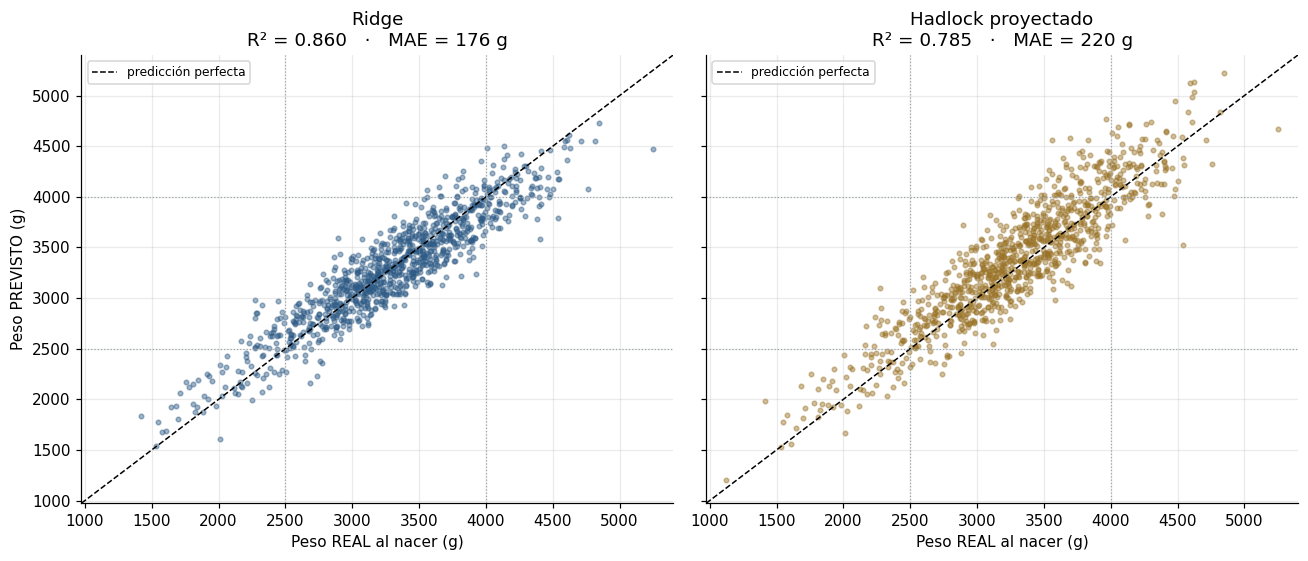

In [20]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 5.2), sharey=True)
for ax, nombre, color in [(ejes[0], "Ridge", AZUL), (ejes[1], "Hadlock proyectado", OCRE)]:
    p = predicciones[nombre]
    r2 = r2_score(y_pru, p)
    mae = mean_absolute_error(y_pru, p)
    ax.scatter(y_pru, p, s=9, alpha=0.45, color=color)
    lim = [y_pru.min() - 150, y_pru.max() + 150]
    ax.plot(lim, lim, color="black", lw=1, ls="--", label="predicción perfecta")
    for corte in (2500, 4000):
        ax.axvline(corte, color=GRIS, lw=0.8, ls=":")
        ax.axhline(corte, color=GRIS, lw=0.8, ls=":")
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f"{nombre}\nR² = {r2:.3f}   ·   MAE = {mae:.0f} g")
    ax.set_xlabel("Peso REAL al nacer (g)")
    ax.legend(loc="upper left", fontsize=8)
ejes[0].set_ylabel("Peso PREVISTO (g)")
plt.tight_layout()
plt.show()

### 8.2 Los errores: la regresión hacia la media

Error = previsto − real. Por encima de 0 el modelo **se pasó**; por debajo,
**se quedó corto**.

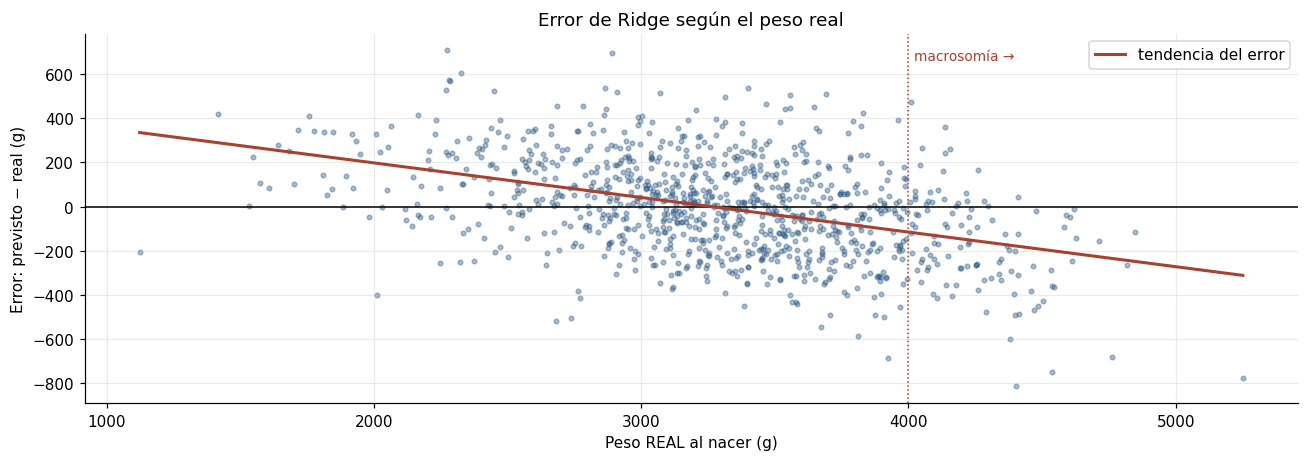

En los bebés de más de 4.000 g, el modelo se queda corto de media por 174 g.


In [21]:
fig, ax = plt.subplots(figsize=(12, 4.3))
error = predicciones["Ridge"] - y_pru.values
ax.scatter(y_pru, error, s=9, alpha=0.4, color=AZUL)
ax.axhline(0, color="black", lw=1)
tendencia = np.polyfit(y_pru, error, 1)
xs = np.linspace(y_pru.min(), y_pru.max(), 50)
ax.plot(xs, np.polyval(tendencia, xs), color=ROJO, lw=2, label="tendencia del error")
ax.axvline(4000, color=ROJO, ls=":", lw=1)
ax.text(4020, ax.get_ylim()[1] * 0.85, "macrosomía →", color=ROJO, fontsize=9)
ax.set_title("Error de Ridge según el peso real")
ax.set_xlabel("Peso REAL al nacer (g)")
ax.set_ylabel("Error: previsto − real (g)")
ax.legend()
plt.tight_layout()
plt.show()

grandes = y_pru.values > 4000
print(f"En los bebés de más de 4.000 g, el modelo se queda corto de media por "
      f"{-error[grandes].mean():.0f} g.")

La línea roja baja hacia la derecha: el modelo **sobreestima a los bebés
pequeños y subestima a los grandes**. Es un efecto conocido de los modelos de
regresión, que tiran las predicciones hacia el centro. Consecuencia práctica:
un bebé de 4.200 g se predice por debajo de 4.000 y se clasifica como normal.
**Por eso la macrosomía es la clase que peor detecta.**

### 8.3 Comparación del error entre modelos

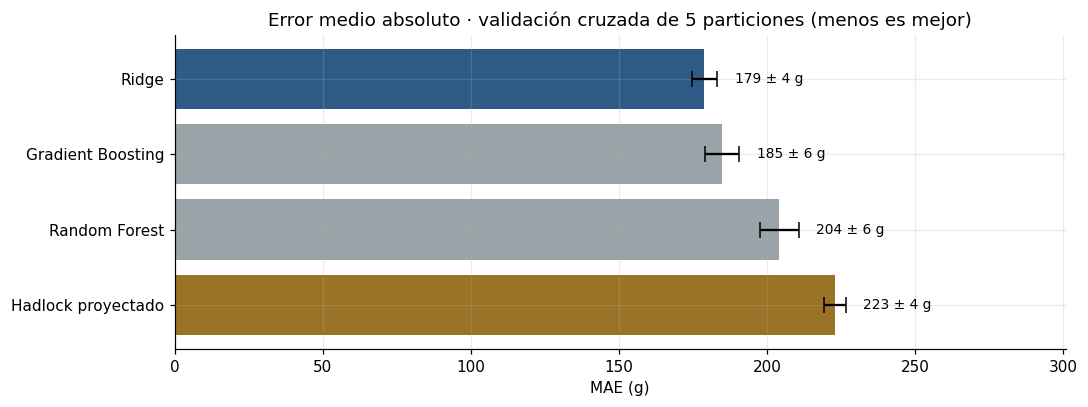

In [22]:
resumen_cv = cv.sort_values("media")
fig, ax = plt.subplots(figsize=(10, 3.8))
colores_barra = [AZUL if n == mejor else OCRE if n == "Hadlock proyectado" else GRIS
                 for n in resumen_cv.index]
ax.barh(resumen_cv.index, resumen_cv["media"], xerr=resumen_cv["desviación"],
        color=colores_barra, capsize=5)
for i, (m, d) in enumerate(zip(resumen_cv["media"], resumen_cv["desviación"])):
    ax.text(m + d + 6, i, f"{m:.0f} ± {d:.0f} g", va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, resumen_cv["media"].max() * 1.35)
ax.set_title("Error medio absoluto · validación cruzada de 5 particiones (menos es mejor)")
ax.set_xlabel("MAE (g)")
plt.tight_layout()
plt.show()

### 8.4 Curvas ROC: ¿qué tan bien separa las clases?

La **curva ROC** muestra, para todos los umbrales posibles, cuántos casos
verdaderos detecta (**sensibilidad**, eje vertical) a cambio de cuántas falsas
alarmas (**1 − especificidad**, eje horizontal).

El **AUC** es el área bajo la curva:
**1,0** = separa perfectamente · **0,5** = no mejor que tirar una moneda (la
línea diagonal).

Como puntuación se usa el propio peso previsto: cuanto más alto, más probable
la macrosomía; cuanto más bajo, más probable el bajo peso.

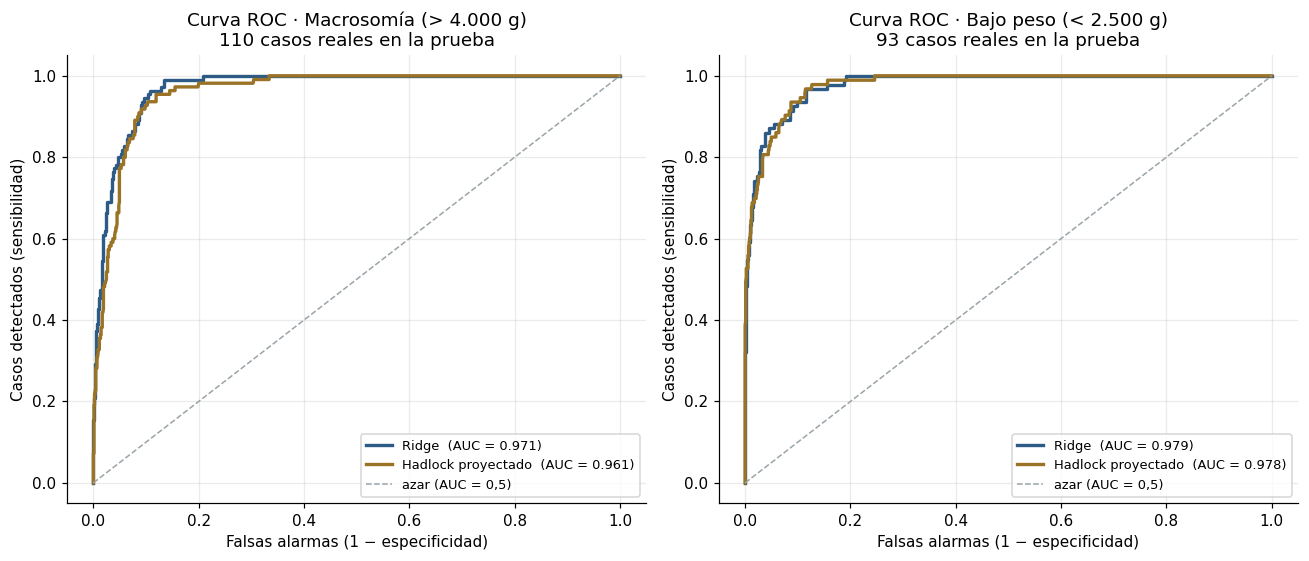

In [23]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 5.2))
casos = [
    ("Macrosomía (> 4.000 g)", (y_pru.values > 4000).astype(int), 1),
    ("Bajo peso (< 2.500 g)", (y_pru.values < 2500).astype(int), -1),
]
auc = {}
for ax, (titulo, verdad, signo) in zip(ejes, casos):
    for nombre, color in [("Ridge", AZUL), ("Hadlock proyectado", OCRE)]:
        puntuacion = signo * predicciones[nombre]
        fpr, tpr, _ = roc_curve(verdad, puntuacion)
        a = roc_auc_score(verdad, puntuacion)
        auc[(titulo, nombre)] = a
        ax.plot(fpr, tpr, color=color, lw=2.2, label=f"{nombre}  (AUC = {a:.3f})")
    ax.plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1, label="azar (AUC = 0,5)")
    ax.set_title(f"Curva ROC · {titulo}\n{verdad.sum()} casos reales en la prueba")
    ax.set_xlabel("Falsas alarmas (1 − especificidad)")
    ax.set_ylabel("Casos detectados (sensibilidad)")
    ax.legend(loc="lower right", fontsize=8.5)
plt.tight_layout()
plt.show()

**Una observación importante.** El AUC puede ser alto y aun así el modelo
detectar pocas macrosomías, como se vio en el paso 7.3. No es una
contradicción: el AUC mide si el modelo **ordena bien** a los bebés de más
pequeño a más grande. La sensibilidad depende además de **dónde se pone el
corte**. Con el corte en 4.000 g, la regresión hacia la media deja fuera a
muchos bebés grandes. La gráfica 8.7 muestra qué pasa si se mueve.

### 8.5 Matrices de confusión

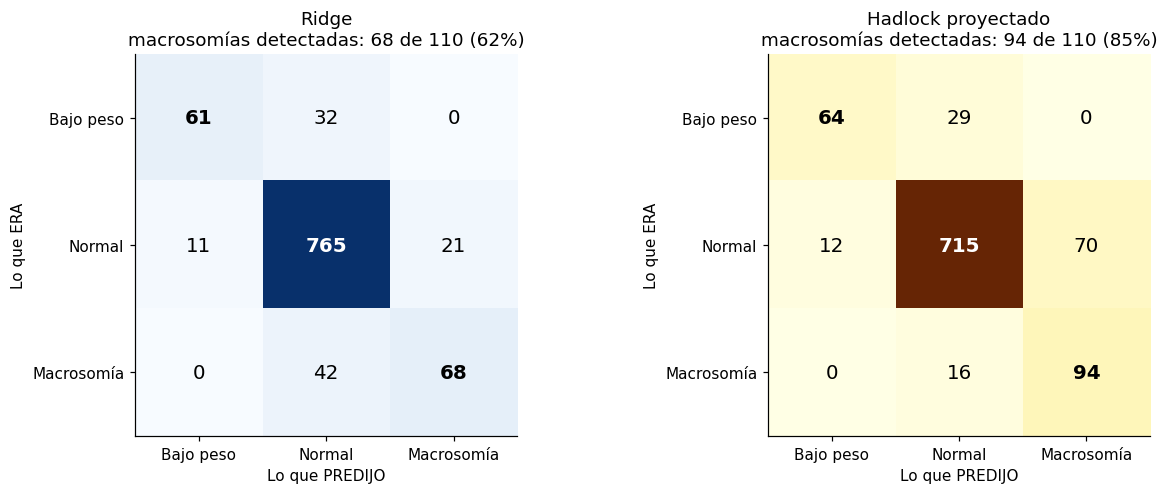

In [24]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.6))
nombres_clase = ["Bajo peso", "Normal", "Macrosomía"]
for ax, nombre, prevista, cmap in [
    (ejes[0], "Ridge", clase_ridge, "Blues"),
    (ejes[1], "Hadlock proyectado", clase_hadlock, "YlOrBr"),
]:
    mc = confusion_matrix(clase_pru, prevista, labels=orden)
    ax.imshow(mc, cmap=cmap)
    ax.grid(False)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, mc[i, j], ha="center", va="center", fontsize=13,
                    color="white" if mc[i, j] > mc.max() / 2 else "black",
                    fontweight="bold" if i == j else "normal")
    ax.set_xticks(range(3), nombres_clase)
    ax.set_yticks(range(3), nombres_clase)
    ax.set_xlabel("Lo que PREDIJO")
    ax.set_ylabel("Lo que ERA")
    sens_macro = mc[2, 2] / mc[2].sum()
    ax.set_title(f"{nombre}\nmacrosomías detectadas: {mc[2, 2]} de {mc[2].sum()} ({sens_macro:.0%})")
plt.tight_layout()
plt.show()

La **diagonal** son los aciertos. Lo que hay fuera son errores; el que más
importa es la fila de **macrosomía** en la columna **normal**: bebés grandes que
se dieron por normales.

### 8.6 ¿Qué variables usa el modelo?

**Importancia por permutación**: se desordena al azar una columna y se mide
cuánto empeora el error. Si empeora mucho, el modelo dependía de esa variable.
Se calcula sobre los datos de **prueba**: una variable puede servir para
memorizar el entrenamiento y no para predecir casos nuevos.

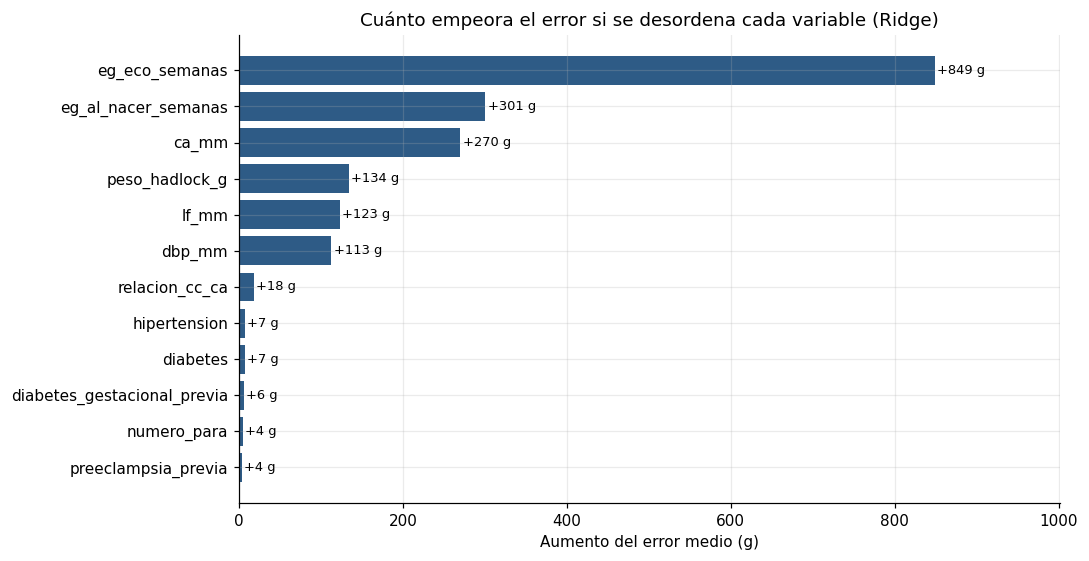

In [25]:
imp = permutation_importance(modelos["Ridge"], X_pru, y_pru,
                             scoring="neg_mean_absolute_error",
                             n_repeats=15, random_state=SEMILLA, n_jobs=-1)
importancia = (pd.Series(imp.importances_mean, index=ENTRADAS)
               .sort_values(ascending=True).tail(12))

fig, ax = plt.subplots(figsize=(10, 5.2))
ax.barh(importancia.index, importancia.values, color=AZUL)
for i, v in enumerate(importancia.values):
    ax.text(v + 3, i, f"+{v:.0f} g", va="center", fontsize=8.5)
ax.set_title("Cuánto empeora el error si se desordena cada variable (Ridge)")
ax.set_xlabel("Aumento del error medio (g)")
ax.set_xlim(0, importancia.max() * 1.18)
plt.tight_layout()
plt.show()

### 8.7 Mover el corte para detectar más macrosomías

La clasificación usa el corte clínico de **4.000 g** sobre el peso previsto.
Pero como el modelo subestima a los bebés grandes, se puede usar un corte **más
bajo** solo para dar la alerta. Detecta más macrosomías a cambio de más falsas
alarmas. Esta gráfica muestra ese intercambio.

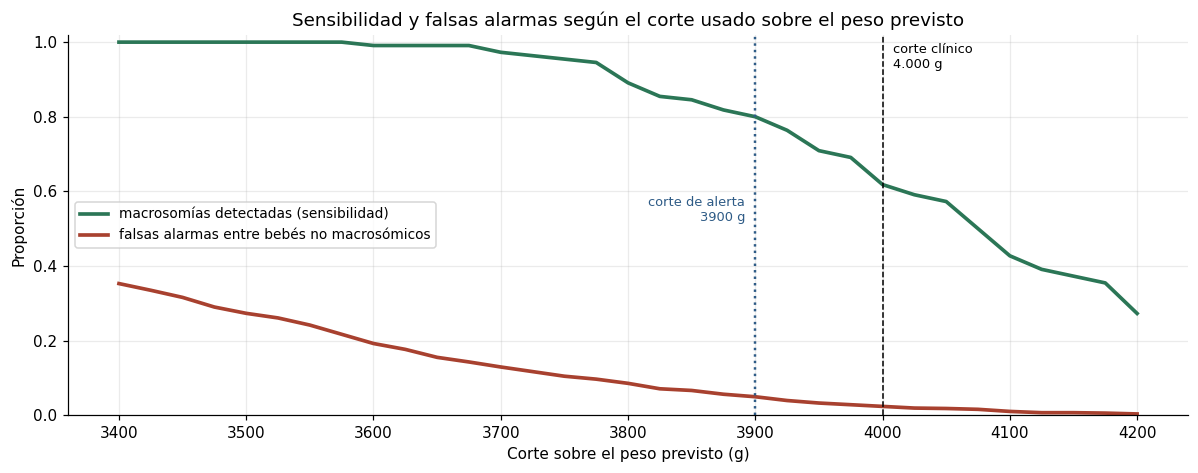

Con el corte de 4.000 g: detecta 62% de las macrosomías con 2.4% de falsas alarmas.
Con un corte de alerta de 3900 g: detecta 80% con 4.9% de falsas alarmas.


In [26]:
es_macro = y_pru.values > 4000
cortes = np.arange(3400, 4201, 25)
sensib = [(predicciones["Ridge"][es_macro] > c).mean() for c in cortes]
falsas = [(predicciones["Ridge"][~es_macro] > c).mean() for c in cortes]

objetivo = 0.80
candidatos = [c for c, s in zip(cortes, sensib) if s >= objetivo]
corte_alerta = max(candidatos) if candidatos else None

fig, ax = plt.subplots(figsize=(11, 4.4))
ax.plot(cortes, sensib, color=VERDE, lw=2.4, label="macrosomías detectadas (sensibilidad)")
ax.plot(cortes, falsas, color=ROJO, lw=2.4, label="falsas alarmas entre bebés no macrosómicos")
ax.axvline(4000, color="black", ls="--", lw=1)
ax.text(4008, 0.93, "corte clínico\n4.000 g", fontsize=8.5)
if corte_alerta:
    ax.axvline(corte_alerta, color=AZUL, ls=":", lw=1.6)
    ax.text(corte_alerta - 8, 0.52, f"corte de alerta\n{corte_alerta} g", fontsize=8.5,
            color=AZUL, ha="right")
ax.set_ylim(0, 1.02)
ax.set_title("Sensibilidad y falsas alarmas según el corte usado sobre el peso previsto")
ax.set_xlabel("Corte sobre el peso previsto (g)")
ax.set_ylabel("Proporción")
ax.legend(loc="center left", fontsize=9)
plt.tight_layout()
plt.show()

i4000 = list(cortes).index(4000)
print(f"Con el corte de 4.000 g: detecta {sensib[i4000]:.0%} de las macrosomías "
      f"con {falsas[i4000]:.1%} de falsas alarmas.")
if corte_alerta:
    j = list(cortes).index(corte_alerta)
    print(f"Con un corte de alerta de {corte_alerta} g: detecta {sensib[j]:.0%} "
          f"con {falsas[j]:.1%} de falsas alarmas.")

### 8.8 Resumen de resultados

In [27]:
ridge_m = metricas(y_pru, predicciones["Ridge"])
hadl_m = metricas(y_pru, predicciones["Hadlock proyectado"])
mc_r = confusion_matrix(clase_pru, clase_ridge, labels=orden)
mc_h = confusion_matrix(clase_pru, clase_hadlock, labels=orden)

resumen = pd.DataFrame({
    "Ridge (el modelo)": [
        f"{ridge_m['MAE (g)']:.0f} g", f"{ridge_m['R²']:.3f}", f"{ridge_m['dentro ±15%']:.1%}",
        f"{auc[('Macrosomía (> 4.000 g)', 'Ridge')]:.3f}",
        f"{auc[('Bajo peso (< 2.500 g)', 'Ridge')]:.3f}",
        f"{mc_r[2, 2] / mc_r[2].sum():.0%}", f"{mc_r[0, 0] / mc_r[0].sum():.0%}",
    ],
    "Hadlock proyectado": [
        f"{hadl_m['MAE (g)']:.0f} g", f"{hadl_m['R²']:.3f}", f"{hadl_m['dentro ±15%']:.1%}",
        f"{auc[('Macrosomía (> 4.000 g)', 'Hadlock proyectado')]:.3f}",
        f"{auc[('Bajo peso (< 2.500 g)', 'Hadlock proyectado')]:.3f}",
        f"{mc_h[2, 2] / mc_h[2].sum():.0%}", f"{mc_h[0, 0] / mc_h[0].sum():.0%}",
    ],
}, index=[
    "Error medio (MAE)", "R²", "Dentro de ±15%",
    "AUC macrosomía", "AUC bajo peso",
    "Sensibilidad macrosomía (corte 4.000 g)", "Sensibilidad bajo peso",
])
print("Veredicto de la validación cruzada:",
      "MEJORA REAL" if mejora_real else ("EMPATE" if media > 0 else "PIERDE"),
      f"({media:+.0f} g, gana en {gana_en} de 5)")
resumen

Veredicto de la validación cruzada: MEJORA REAL (+44 g, gana en 5 de 5)


,Ridge (el modelo),Hadlock proyectado
Error medio (MAE),176 g,220 g
R²,0.860,0.785
Dentro de ±15%,96.2%,91.3%
AUC macrosomía,0.971,0.961
AUC bajo peso,0.979,0.978
Sensibilidad macrosomía (corte 4.000 g),62%,85%
Sensibilidad bajo peso,66%,69%


---
## Cuándo y cómo implementarlo

### De qué se trata

Es una **herramienta de apoyo a la decisión** para la consulta prenatal del
tercer trimestre. La médica ya tiene la ecografía; el modelo le da una
estimación del peso al nacer **junto a** la de la fórmula de Hadlock, para que
compare las dos. **No diagnostica y no sustituye a la fórmula**: la acompaña.

### En qué módulo entra

| Pieza | Dónde está en el sistema |
|---|---|
| La fórmula de Hadlock (arreglada) | `backend/ecografias/peso_fetal.py` |
| Qué 18 variables usa y en qué orden | `backend/ia_medica/ml/caracteristicas_peso.py` |
| Construir la tabla desde la base | `backend/ia_medica/ml/dataset_peso.py` |
| Entrenar, comparar y decidir | `backend/ia_medica/ml/entrenamiento_peso.py` |
| Comandos | `python manage.py construir_dataset_peso` · `python manage.py entrenar_modelo_peso` |
| Dónde se vería en pantalla | Ficha de la ecografía → pestaña **Biometría Fetal**, debajo de las medidas |

El flujo de datos es:
**`ecografias`** (las medidas) + **`embarazos`** y **`pacientes`** (la madre) →
**`ia_medica/ml`** (el modelo) → pantalla de la ecografía.
Y para aprender: **`partos`** (el peso real del recién nacido).

### Cuándo implementarlo

**Todavía no en producción.** Tres condiciones, y hoy no se cumple ninguna:

1. **Tener datos reales.** Estos 5.000 casos son simulados. Hacen falta al menos
   unos 300 partos reales de la clínica con su ecografía del tercer trimestre y
   el peso al nacer, anonimizados.
2. **Que el modelo mejore a Hadlock sobre esos datos reales**, con el criterio
   del paso 7.2: ganar en todas las particiones y por más de dos errores
   estándar. Con los 5.000 simulados lo consigue; con los 277 casos que tiene
   hoy el sistema, el resultado fue un **empate**.
3. **Que detecte bien la macrosomía.** Con el corte de 4.000 g se le escapan
   muchas. Habría que usar un corte de alerta más bajo (paso 8.7) y validarlo
   con una médica.

### Un primer paso que no necesita el modelo

El paso 7.3 enseña que parte de la ventaja se consigue **sin aprendizaje
automático**: si en la clínica real Hadlock se pasa siempre en la misma
dirección, basta con **corregirlo con un factor local** aprendido de los partos
propios. Es más simple, más fácil de auditar y se puede hacer antes de tener
datos suficientes para entrenar un modelo. Solo cuando haya datos para medir
si los factores maternos añaden algo por encima de esa corrección tiene sentido
pasar al modelo completo.

### Cómo implementarlo, cuando se cumplan

1. Reunir los datos reales en la base del sistema. El comando
   `construir_dataset_peso` ya los convierte en la tabla de entrenamiento.
2. Ejecutar `entrenar_modelo_peso`. El propio comando **se niega a guardar el
   modelo** si no mejora a Hadlock.
3. Si mejora, se guarda y se muestra en la pestaña **Biometría Fetal** con:
   el peso previsto y su margen de error, la clase, **el valor de Hadlock al
   lado**, y el aviso de que es una estimación de apoyo.
4. Cada predicción se guarda con sus datos de entrada y la versión del modelo.
   Cuando el bebé nace, se compara con el peso real. **Ese error, medido sobre
   nacimientos reales, es el resultado que vale.**